# Asteroid Dataset: Collection and Exploration

**Course:** CSC17104 — Programming for Data Science  
**Input:** `data/raw/dataset.csv`  
**Scope:** Data documentation, quality checks, exploratory plots, and a preprocessing plan.

## How to use this notebook

Save this notebook in `P4DS/notebooks/`. Select the `asteroid-pds` kernel, then use **Restart Kernel and Run All**. The CSV is loaded once; subsequent cells reuse `df`. No cell overwrites the raw CSV or automatically removes records.

**Output provenance:** Retained outputs come from the uploaded notebook. Edited code cells have their outputs cleared and must be rerun. The CSV was not supplied with this revision, so a fresh full-data execution has not been performed here.

**Before submission:** Confirm the dataset license, exact downloaded version/date, team motivation, and related public notebooks. Review the findings in your own words and record significant AI assistance in `LLM_USAGE.md`.


## 1. Project and dataset overview

This project explores the physical properties, orbital parameters, and classifications recorded in the Asteroid Dataset. Each row represents an object record rather than a time-series observation. Identification fields support checks for repeated objects; physical and orbital fields support subsequent exploratory comparisons.

- **Dataset:** [Asteroid Dataset on Kaggle](https://www.kaggle.com/datasets/sakhawat18/asteroid-dataset).
- **Downloaded filename:** `dataset.csv`.
- **Size in the supplied execution:** 958,524 rows and 45 columns.
- **Scope:** A catalogue snapshot; it should not be assumed to represent every asteroid in the Solar System or a random population sample.
- **Team motivation — author input required:** Explain why your team selected this topic and what you hope to learn.
- **Version and download date — confirmation required:** Record the version and date associated with your local CSV. Do not substitute a current website update date.


## 2. Source, license, and collection method

| Item | Documentation |
|---|---|
| Distribution platform | Kaggle; dataset account `sakhawat18` |
| Dataset URL | https://www.kaggle.com/datasets/sakhawat18/asteroid-dataset |
| Upstream source referenced by the dataset page | NASA/JPL Small-Body Database (SBDB) |
| Collection and processing | JPL computes orbital solutions from observational data, including observations published by the Minor Planet Center and radar astrometry where available. This CSV is a catalogue export, not a table of individual raw telescope observations. |
| Technical documentation | [JPL SBDB API](https://ssd-api.jpl.nasa.gov/doc/sbdb.html) and [field definitions](https://ssd-api.jpl.nasa.gov/doc/sbdb_query.html) |
| License and attribution | **Not yet verified for the downloaded Kaggle version.** Record the exact license and any attribution requirements before submission. Public access alone does not establish a license. |
| Publication date and observation period | **Not established from the supplied notebook.** Verify from the source; orbital epochs are not discovery dates or the observation period. |
| Related public notebooks | **Team review required.** List the notebooks actually consulted and explain how the team's questions differ. |

### Scope and limitations to consider

Catalogue inclusion depends on discovery and observation. Physical measurements are not equally available for all objects. Consequently, comparisons restricted to measured diameters may describe a selected subset rather than the full catalogue. Assess this limitation using the missingness checks below; do not assume missing values are random.


## 3. Load the data

Put the downloaded CSV in `data/raw/`. Update the filename below. 


In [30]:
from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "dataset.csv"

if not DATA_PATH.is_file():
    raise FileNotFoundError(f"File not found: {DATA_PATH}")

df = pd.read_csv(DATA_PATH, low_memory=False)


print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
display(df.head())
df.info(show_counts=True, memory_usage="deep")

Rows: 958,524
Columns: 45


,id,spkid,full_name,pdes,name,prefix,neo,pha,H,diameter,...,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,class,rms
0,a0000001,2000001,1 Ceres,1,Ceres,NaN,N,N,3.40,939.400,...,4.608900e-09,6.168800e-08,6.624800e-08,7.820700e-09,1.111300e-11,1.196500e-12,3.782900e-08,9.415900e-09,MBA,0.43301
1,a0000002,2000002,2 Pallas,2,Pallas,NaN,N,N,4.20,545.000,...,3.469400e-06,6.272400e-06,9.128200e-06,8.859100e-06,4.961300e-09,4.653600e-10,4.078700e-05,3.680700e-06,MBA,0.35936
2,a0000003,2000003,3 Juno,3,Juno,NaN,N,N,5.33,246.596,...,3.223100e-06,1.664600e-05,1.772100e-05,8.110400e-06,4.363900e-09,4.413400e-10,3.528800e-05,3.107200e-06,MBA,0.33848
3,a0000004,2000004,4 Vesta,4,Vesta,NaN,N,N,3.00,525.400,...,2.170600e-07,3.880800e-07,1.789300e-07,1.206800e-06,1.648600e-09,2.612500e-10,4.103700e-06,1.274900e-06,MBA,0.39980
4,a0000005,2000005,5 Astraea,5,Astraea,NaN,N,N,6.90,106.699,...,2.740800e-06,2.894900e-05,2.984200e-05,8.303800e-06,4.729000e-09,5.522700e-10,3.474300e-05,3.490500e-06,MBA,0.52191


<class 'pandas.DataFrame'>
RangeIndex: 958524 entries, 0 to 958523
Data columns (total 45 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id              958524 non-null  str    
 1   spkid           958524 non-null  int64  
 2   full_name       958524 non-null  str    
 3   pdes            958524 non-null  str    
 4   name            22064 non-null   str    
 5   prefix          18 non-null      str    
 6   neo             958520 non-null  str    
 7   pha             938603 non-null  str    
 8   H               952261 non-null  float64
 9   diameter        136209 non-null  float64
 10  albedo          135103 non-null  float64
 11  diameter_sigma  136081 non-null  float64
 12  orbit_id        958524 non-null  str    
 13  epoch           958524 non-null  float64
 14  epoch_mjd       958524 non-null  int64  
 15  epoch_cal       958524 non-null  float64
 16  equinox         958524 non-null  str    
 17  e               95852

## 4. Dataset structure and row meaning

The dataset is organized as a table. Each row contains a record
about an asteroid, while each column describes an attribute,
such as identification information, physical properties, or
orbital parameters.

In this section, we check the `id` and `spkid` columns for missing
and repeated identifiers. These checks help determine whether
each object is uniquely represented in the dataset.

The meaning, unit, and data type of each column are described
in Section 5 – Column dictionary.

In [31]:
for col in ["id", "spkid"]:
    if col in df.columns:
        print(f"\nColumn: {col}")
        print("Missing values:", df[col].isna().sum())
        print("Unique identifiers:", df[col].nunique())
        print("Repeated identifiers beyond the first occurrence:",
              df[col].dropna().duplicated().sum())


Column: id
Missing values: 0
Unique identifiers: 958524
Repeated identifiers beyond the first occurrence: 0

Column: spkid
Missing values: 0
Unique identifiers: 958524
Repeated identifiers beyond the first occurrence: 0


## 5. Column dictionary

This section documents the meaning, unit, and data type of each
column. Definitions and units are checked against the dataset
documentation, while data types are obtained from the loaded CSV.

### 5.1. Loaded data types


In [32]:
column_types = pd.DataFrame({
    "Column": df.columns,
    "Data type": df.dtypes.astype(str).to_numpy()
})

with pd.option_context("display.max_rows", None):
    display(column_types)

,Column,Data type
0,id,str
1,spkid,int64
2,full_name,str
3,pdes,str
4,name,str
5,prefix,str
6,neo,str
7,pha,str
8,H,float64
9,diameter,float64


### 5.2. Column groups

The columns are grouped by their purpose:

| Group | Columns | Role |
|---|---|---|
| Identification | `id`, `spkid`, `full_name`, `pdes`, `name`, `prefix` | Identify and label objects. |
| Physical properties | `H`, `diameter`, `albedo`, `diameter_sigma` | Describe brightness, size, reflectivity, and diameter uncertainty. |
| Classification | `neo`, `pha`, `class` | Describe near-Earth status, potentially hazardous status, and orbital class. |
| Orbital parameters | `e`, `a`, `q`, `i`, `om`, `w`, `ma`, `ad`, `n`, `per`, `per_y` | Describe orbital geometry and motion. |
| Earth-orbit proximity | `moid`, `moid_ld` | Describe the minimum separation between the object's orbit and Earth's orbit. |
| Time and reference information | `orbit_id`, `epoch`, `epoch_mjd`, `epoch_cal`, `equinox`, `tp`, `tp_cal` | Identify the orbit solution, reference epoch, reference frame, and perihelion time. |
| Uncertainty and fit quality | All `sigma_*` columns and `rms` | Describe parameter uncertainty and the quality of the orbit fit. |

### 5.3. Main columns for initial exploration

#### Physical properties

- **`H` — Absolute magnitude:** A measure of brightness under
  standardized viewing conditions. A lower value indicates a
  brighter object. It is not a direct measurement of diameter.

- **`diameter` — Effective diameter (km):** Describes the object's
  size using an equivalent-sphere representation.

- **`albedo` — Geometric albedo:** A dimensionless measure of
  reflectivity. Diameter estimates depend on both brightness
  and albedo, so these three variables should be interpreted together.

- **`diameter_sigma` — Diameter uncertainty (km):** The reported
  one-standard-deviation uncertainty in diameter. This helps
  distinguish the estimated size from its precision.

#### Orbital properties

| Column | Meaning | Unit |
|---|---|---|
| `e` | Eccentricity: describes orbital shape; zero corresponds to a circle. | Dimensionless |
| `a` | Semi-major axis: describes orbital size for an elliptical orbit. | au |
| `q` | Perihelion distance: the closest orbital distance to the Sun. | au |
| `ad` | Aphelion distance: the farthest orbital distance from the Sun for an elliptical orbit. | au |
| `i` | Inclination: the tilt relative to the reference ecliptic plane. | Degrees |
| `om` | Longitude of the ascending node: describes orbital orientation. | Degrees |
| `w` | Argument of perihelion: describes perihelion orientation within the orbital plane. | Degrees |
| `ma` | Mean anomaly: describes orbital phase at the reference epoch. | Degrees |
| `n` | Mean motion: the average rate of change of mean anomaly. | Degrees/day |
| `per` | Orbital period. | Days |
| `per_y` | Orbital period expressed in years. | Years |

For initial exploration, `e`, `a`, `q`, `i`, and `per_y` are
reasonable starting points. Other orbital parameters can be
examined when relevant to a specific question.

#### Classification and Earth-orbit proximity

- **`neo`:** Indicates whether the object is classified as a
  Near-Earth Object. For asteroids, the classification is based
  on a perihelion distance below 1.3 au.

- **`pha`:** Indicates Potentially Hazardous Asteroid status.
  The classification uses Earth MOID ≤ 0.05 au and H ≤ 22.
  It does not mean that an impact is predicted.

- **`class`:** The orbital classification code. It provides a
  grouping variable for comparing objects with different orbits.

- **`moid`:** Earth Minimum Orbit Intersection Distance, in au.
  It measures the minimum separation between two orbital paths,
  not the current distance between Earth and the asteroid.

- **`moid_ld`:** The same orbital-distance measure expressed
  in lunar distances.

### 5.4. Interpretation and preprocessing notes

1. **Identifiers are not quantitative measurements.**
   Although `spkid` is loaded as `int64`, arithmetic operations
   such as averaging its values have no scientific meaning.
   Prefer `spkid` or `pdes` to the internal `id` for persistent
   object identification.

2. **Several columns express the same information differently.**
   Examples include `per` and `per_y`, `moid` and `moid_ld`,
   and the three `epoch` representations. Avoid treating them
   as independent measurements.

3. **Time-like numbers require interpretation.**
   `epoch` is a Julian Date, `epoch_mjd` is a Modified Julian
   Date, and `epoch_cal` is a calendar representation.
   Check actual values before converting calendar fields.
   The orbital epoch is not the object's discovery date.

4. **Uncertainty is different from the parameter itself.**
   Each `sigma_*` column gives the reported one-standard-deviation
   uncertainty of its corresponding orbital parameter, using
   the parameter's units. `sigma_tp` is expressed in days.
   `rms` describes the normalized residual fit of orbital
   observations; it is not an impact-risk score.

5. **Classification rules matter when designing ML tasks.**
   Predicting `pha` from `H` and `moid` may largely reproduce
   its definition. Likewise, predicting `neo` from `q` may
   reproduce the near-Earth classification rule. Such tasks
   require careful justification before being selected.

6. **These priorities are provisional.**
   No column is removed solely because it is outside the
   initial exploration list. Missingness, scientific meaning,
   and the final research questions will guide later decisions.


## 6. Duplicates and data quality

This section checks for duplicate rows, entirely empty rows,
missing values, and inconsistent text labels. No records are
removed or imputed at this stage. Any cleaning decisions will
be based on the checks below and the meaning of each column.

### 6.1. Duplicate and empty records


In [33]:
duplicate_mask = df.duplicated()
empty_mask = df.isna().all(axis=1)

print(f"Total rows: {len(df):,}")
print(f"Duplicate rows beyond the first occurrence: {duplicate_mask.sum():,}")
print(f"Entirely empty rows: {empty_mask.sum():,}")

if duplicate_mask.any():
    display(df.loc[duplicate_mask].head())

Total rows: 958,524
Duplicate rows beyond the first occurrence: 0
Entirely empty rows: 0


### 6.2. Missingness and distinct values


In [34]:
quality_summary = pd.DataFrame({
    "Data type": df.dtypes.astype(str),
    "Missing count": df.isna().sum(),
    "Missing (%)": df.isna().mean().mul(100),
    "Unique non-missing values": df.nunique()
})

quality_summary = quality_summary.sort_values(
    "Missing (%)", ascending=False
)

with pd.option_context("display.max_rows", None):
    display(quality_summary.round({"Missing (%)": 2}))

,Data type,Missing count,Missing (%),Unique non-missing values
prefix,str,958506,100.00,1
name,str,936460,97.70,22064
albedo,float64,823421,85.91,1057
diameter_sigma,float64,822443,85.80,3054
diameter,float64,822315,85.79,16591
sigma_per,float64,19926,2.08,282687
sigma_ad,float64,19926,2.08,269241
sigma_om,float64,19922,2.08,223155
sigma_ma,float64,19922,2.08,266816
sigma_q,float64,19922,2.08,248138


### 6.3. Text formatting


In [35]:
text_columns = df.select_dtypes(
    include=["object", "string"]
).columns

text_checks = []

for col in text_columns:
    values = df[col].astype("string")
    stripped = values.str.strip()

    text_checks.append({
        "Column": col,
        "Blank or whitespace-only": int(
            stripped.eq("").fillna(False).sum()
        ),
        "Leading or trailing whitespace": int(
            values.ne(stripped).fillna(False).sum()
        )
    })

display(pd.DataFrame(text_checks))

,Column,Blank or whitespace-only,Leading or trailing whitespace
0,id,0,0
1,full_name,0,513388
2,pdes,0,0
3,name,0,0
4,prefix,0,0
5,neo,0,0
6,pha,0,0
7,orbit_id,0,0
8,equinox,0,0
9,class,0,0


### 6.4. Metadata labels


In [36]:
for col in ["prefix", "equinox"]:
    if col in df.columns:
        print(f"\nColumn: {col}")
        display(
            df[col]
            .value_counts(dropna=False)
            .rename_axis("Value")
            .reset_index(name="Count")
        )


Column: prefix


,Value,Count
0,NaN,958506
1,A,18



Column: equinox


,Value,Count
0,J2000,958524


## 7. Numerical columns

This section examines the distributions and ranges of selected
physical and orbital variables. Identifier columns are excluded
from numerical summaries.

We inspect summary statistics, distribution plots, and basic
validity checks. Extreme values are flagged for further review
rather than automatically removed.

### 7.1. Descriptive statistics


In [37]:
import matplotlib.pyplot as plt

selected_columns = [
    "H", "diameter", "albedo",
    "e", "a", "q", "ad", "i",
    "per_y", "moid"
]

numeric_columns = [
    col for col in selected_columns
    if col in df.columns and pd.api.types.is_numeric_dtype(df[col])
]

summary = df[numeric_columns].describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]
).T

summary["missing_percent"] = (
    df[numeric_columns].isna().mean().mul(100)
)

display(summary.round(4))

,count,mean,std,min,1%,25%,50%,75%,99%,max,missing_percent
H,952261.0,16.9064,1.7904,-1.1000,12.6000,16.1000,16.9000,17.7140,23.8000,3.320000e+01,0.6534
diameter,136209.0,5.5064,9.4252,0.0025,1.2510,2.7800,3.9720,5.7650,32.1165,9.394000e+02,85.7897
albedo,135103.0,0.1306,0.1103,0.0010,0.0250,0.0530,0.0790,0.1900,0.4670,1.000000e+00,85.9051
e,958524.0,0.1561,0.0926,0.0000,0.0178,0.0922,0.1450,0.2007,0.5132,1.855400e+00,0.0000
a,958524.0,2.9021,39.7195,-14702.4479,1.5600,2.3878,2.6470,3.0019,5.1744,3.348890e+04,0.0000
q,958524.0,2.3949,2.1392,0.0705,0.9169,1.9714,2.2258,2.5783,4.7298,8.039880e+01,0.0000
ad,958520.0,3.4558,71.7694,0.6538,1.9426,2.7816,3.0470,3.3648,5.4828,6.697280e+04,0.0004
i,958524.0,9.0549,6.6377,0.0077,0.7463,4.1654,7.4157,12.4076,29.0796,1.750829e+02,0.0000
per_y,958523.0,13.9229,6321.5808,0.0000,1.9485,3.6899,4.3066,5.2013,11.7705,6.128574e+06,0.0001
moid,938603.0,1.4152,2.1567,0.0000,0.0355,0.9797,1.2408,1.5934,3.7604,7.947660e+01,2.0783


### 7.2. Basic validity checks


In [38]:
finite_checks = pd.DataFrame({
    "Column": numeric_columns,
    "Infinite values": [
        np.isinf(df[col]).sum()
        for col in numeric_columns
    ]
})

display(finite_checks)

range_rules = {
    "diameter": ("Diameter <= 0", lambda s: s <= 0),
    "albedo": ("Albedo < 0", lambda s: s < 0),
    "e": ("Eccentricity < 0", lambda s: s < 0),
    "q": ("Perihelion distance <= 0", lambda s: s <= 0),
    "i": ("Inclination outside [0, 180]", lambda s: (s < 0) | (s > 180)),
    "per_y": ("Orbital period <= 0", lambda s: s <= 0),
    "moid": ("Earth MOID < 0", lambda s: s < 0)
}

range_results = []

for col, (description, rule) in range_rules.items():
    if col in numeric_columns:
        finite_values = df.loc[np.isfinite(df[col]), col]
        flagged = rule(finite_values)

        range_results.append({
            "Column": col,
            "Check": description,
            "Values checked": len(finite_values),
            "Flagged values": int(flagged.sum())
        })

display(pd.DataFrame(range_results))

,Column,Infinite values
0,H,0
1,diameter,0
2,albedo,0
3,e,0
4,a,0
5,q,0
6,ad,0
7,i,0
8,per_y,0
9,moid,0


,Column,Check,Values checked,Flagged values
0,diameter,Diameter <= 0,136209,0
1,albedo,Albedo < 0,135103,0
2,e,Eccentricity < 0,958524,0
3,q,Perihelion distance <= 0,958524,0
4,i,"Inclination outside [0, 180]",958524,0
5,per_y,Orbital period <= 0,958523,3
6,moid,Earth MOID < 0,938603,0


### 7.3. Full-range distributions


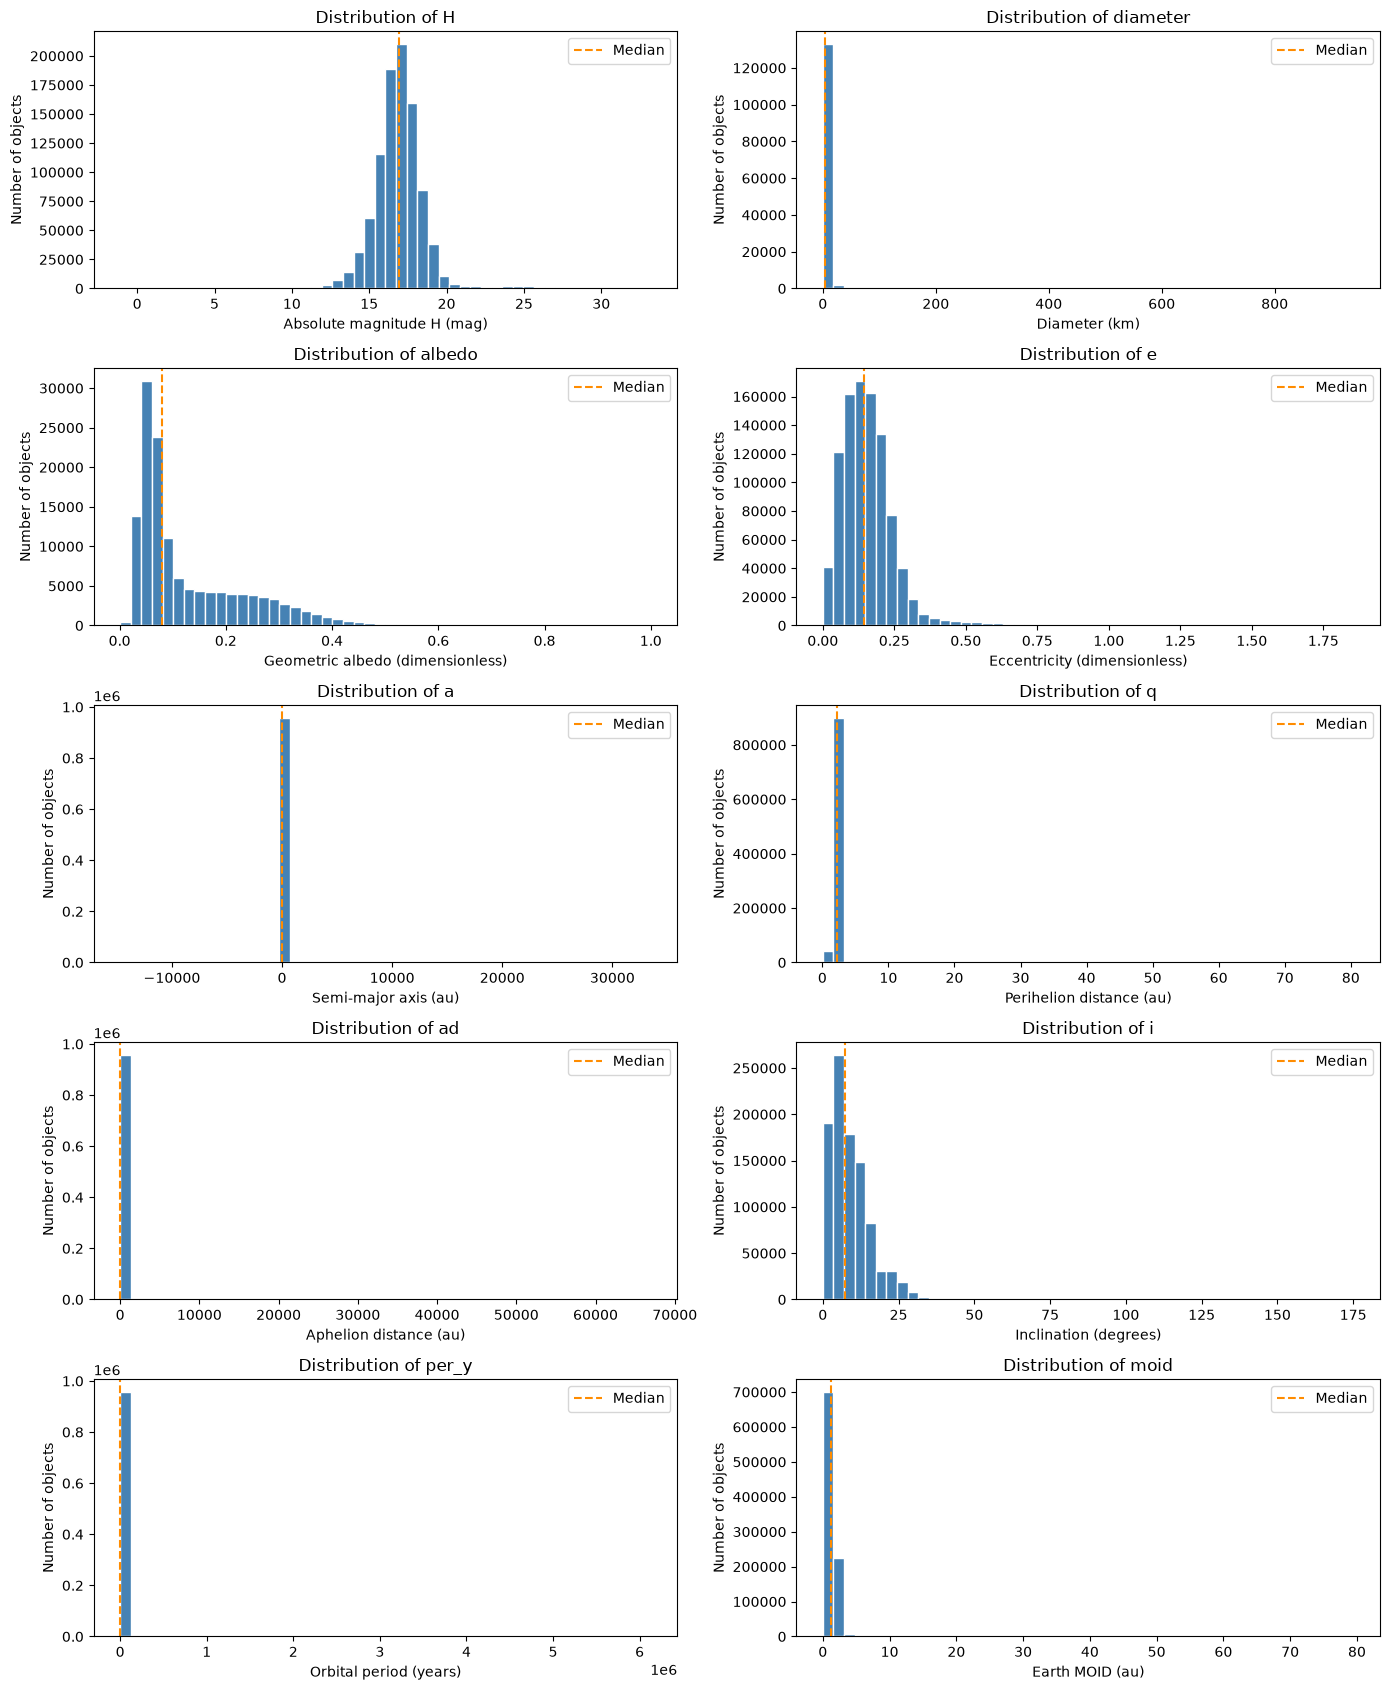

In [39]:
plot_labels = {
    "H": "Absolute magnitude H (mag)",
    "diameter": "Diameter (km)",
    "albedo": "Geometric albedo (dimensionless)",
    "e": "Eccentricity (dimensionless)",
    "a": "Semi-major axis (au)",
    "q": "Perihelion distance (au)",
    "ad": "Aphelion distance (au)",
    "i": "Inclination (degrees)",
    "per_y": "Orbital period (years)",
    "moid": "Earth MOID (au)"
}

ncols = 2
nrows = (len(numeric_columns) + ncols - 1) // ncols

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(14, 3.4 * nrows),
    squeeze=False
)

for ax, col in zip(axes.flat, numeric_columns):
    values = df.loc[np.isfinite(df[col]), col]

    if values.empty:
        ax.set_title(f"{col}: no finite values")
        ax.set_axis_off()
        continue

    ax.hist(values, bins=50, color="steelblue", edgecolor="white")
    ax.axvline(
        values.median(),
        color="darkorange",
        linestyle="--",
        label="Median"
    )

    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(plot_labels[col])
    ax.set_ylabel("Number of objects")
    ax.legend()

for ax in list(axes.flat)[len(numeric_columns):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

### 7.4. Inspect the largest recorded diameters


In [40]:
if "diameter" in numeric_columns:
    inspection_columns = [
        col for col in [
            "spkid", "full_name", "diameter",
            "diameter_sigma", "H", "albedo", "class"
        ]
        if col in df.columns
    ]

    display(
        df.loc[np.isfinite(df["diameter"])]
        .nlargest(10, "diameter")[inspection_columns]
    )
    

,spkid,full_name,diameter,diameter_sigma,H,albedo,class
0,2000001,1 Ceres,939.400,0.200,3.4,0.0900,MBA
19999,2020000,20000 Varuna (2000 WR106),900.000,140.000,3.6,0.0700,TNO
1,2000002,2 Pallas,545.000,18.000,4.2,0.1010,MBA
3,2000004,4 Vesta,525.400,0.200,3.0,0.4228,MBA
9,2000010,10 Hygiea,407.120,6.800,5.5,0.0717,MBA
15788,2015789,15789 (1993 SC),328.000,60.000,7.0,0.0220,TNO
703,2000704,704 Interamnia (1910 KU),306.313,1.031,6.4,0.0780,MBA
51,2000052,52 Europa,303.918,3.501,6.4,0.0570,MBA
10198,2010199,10199 Chariklo (1997 CU26),302.000,30.000,6.6,0.0450,CEN
510,2000511,511 Davida (1903 LU),270.327,1.045,6.3,0.0760,MBA


## 8. Categorical columns

This section examines the frequencies and proportions of
near-Earth status (`neo`), potentially hazardous status (`pha`),
and orbital class (`class`).

Identifiers and object names are excluded from category plots.
Missing values are shown separately and are not treated as
negative classifications.

### 8.1. Category frequencies


In [41]:
categorical_columns = [
    col for col in ["neo", "pha", "class"]
    if col in df.columns
]

category_tables = {}

for col in categorical_columns:
    counts = df[col].value_counts(dropna=False)

    table = counts.rename_axis("Category").reset_index(name="Count")
    table["Percentage (%)"] = table["Count"] / len(df) * 100

    category_tables[col] = table

    print(f"\nColumn: {col}")
    display(table.round({"Percentage (%)": 2}))


Column: neo


,Category,Count,Percentage (%)
0,N,935625,97.61
1,Y,22895,2.39
2,NaN,4,0.00



Column: pha


,Category,Count,Percentage (%)
0,N,936537,97.71
1,NaN,19921,2.08
2,Y,2066,0.22



Column: class


,Category,Count,Percentage (%)
0,MBA,855954,89.30
1,OMB,28355,2.96
2,IMB,20360,2.12
3,MCA,18685,1.95
4,APO,12687,1.32
5,AMO,8457,0.88
6,TJN,8221,0.86
7,TNO,3468,0.36
8,ATE,1729,0.18
9,CEN,506,0.05


### 8.2. Category proportions


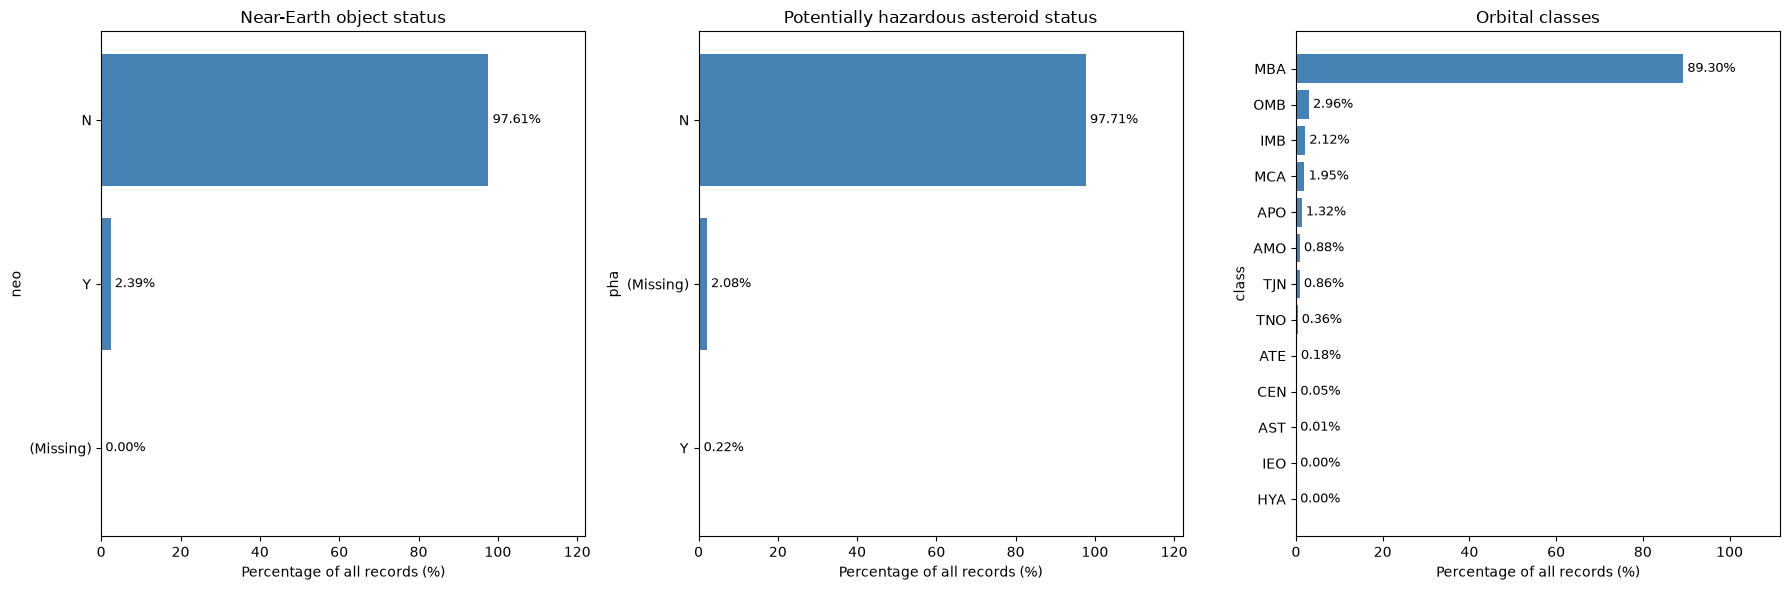

In [42]:
titles = {
    "neo": "Near-Earth object status",
    "pha": "Potentially hazardous asteroid status",
    "class": "Orbital classes"
}

fig, axes = plt.subplots(
    1, len(categorical_columns),
    figsize=(18, 6),
    squeeze=False
)

for ax, col in zip(axes.flat, categorical_columns):
    table = category_tables[col].sort_values(
        "Count", ascending=True
    )

    labels = (
        table["Category"]
        .astype("string")
        .fillna("(Missing)")
    )

    bars = ax.barh(
        labels,
        table["Percentage (%)"],
        color="steelblue"
    )

    ax.bar_label(bars, fmt="%.2f%%", padding=3, fontsize=9)
    ax.set_title(titles[col])
    ax.set_xlabel("Percentage of all records (%)")
    ax.set_ylabel(col)
    ax.margins(x=0.25)

plt.tight_layout()
plt.show()

### 8.3. Small orbital classes


In [43]:
if "class" in category_tables:
    class_table = category_tables["class"]

    rare_classes = class_table.loc[
        class_table["Category"].notna()
        & (class_table["Percentage (%)"] < 1)
    ]

    print("Orbital classes representing less than 1% of all records:")
    display(rare_classes.round({"Percentage (%)": 2}))

Orbital classes representing less than 1% of all records:


,Category,Count,Percentage (%)
5,AMO,8457,0.88
6,TJN,8221,0.86
7,TNO,3468,0.36
8,ATE,1729,0.18
9,CEN,506,0.05
10,AST,76,0.01
11,IEO,22,0.00
12,HYA,4,0.00


## 9. Relationships and preliminary patterns

This section explores relationships between selected numerical
variables and differences across orbital classes.

The analysis is exploratory. Associations do not establish
causation, and some relationships may reflect physical equations
or classification rules rather than independent discoveries.

Missing values are handled separately for each comparison.
The original dataset remains unchanged.

### 9.1. Diameter and absolute magnitude


Original rows: 958,524
Rows with finite H and diameter: 132,045
Rows with positive diameter: 132,045
Rows plotted: 10,000


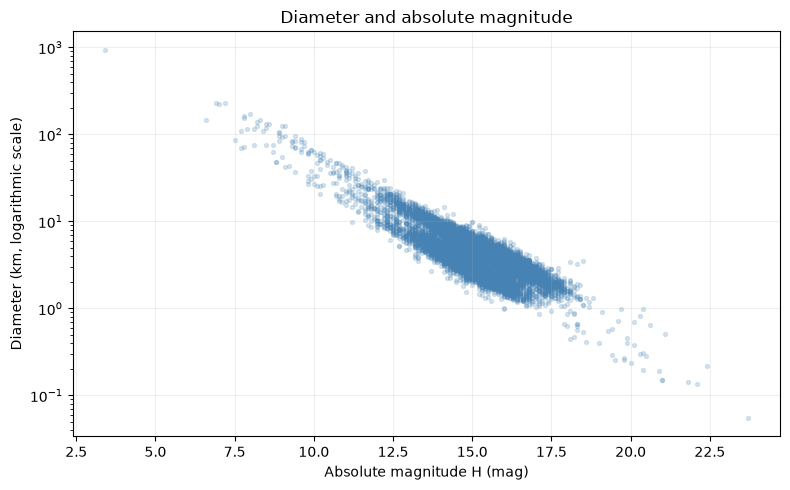

In [44]:
physical_data = (
    df[["H", "diameter"]]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

print(f"Original rows: {len(df):,}")
print(f"Rows with finite H and diameter: {len(physical_data):,}")

physical_data = physical_data.loc[
    physical_data["diameter"] > 0
]

print(f"Rows with positive diameter: {len(physical_data):,}")

plot_sample = physical_data.sample(
    n=min(10_000, len(physical_data)),
    random_state=42
)

print(f"Rows plotted: {len(plot_sample):,}")

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    plot_sample["H"],
    plot_sample["diameter"],
    s=8,
    alpha=0.2,
    color="steelblue"
)

ax.set_yscale("log")
ax.set_xlabel("Absolute magnitude H (mag)")
ax.set_ylabel("Diameter (km, logarithmic scale)")
ax.set_title("Diameter and absolute magnitude")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### 9.2. Eccentricity across orbital classes


Original rows: 958,524
Rows with orbital class and finite eccentricity: 958,524
Rows excluded from this comparison: 0


,count,median,q25,q75
class,,,,
TJN,8221,0.0678,0.0442,0.0939
IMB,20360,0.0763,0.0580,0.0936
OMB,28355,0.1262,0.0797,0.1878
MBA,855954,0.1448,0.0938,0.1960
TNO,3468,0.1511,0.0706,0.2855
MCA,18685,0.3030,0.2338,0.3813
ATE,1729,0.3033,0.2001,0.4222
IEO,22,0.3417,0.2209,0.4483
AST,76,0.4235,0.3590,0.5170


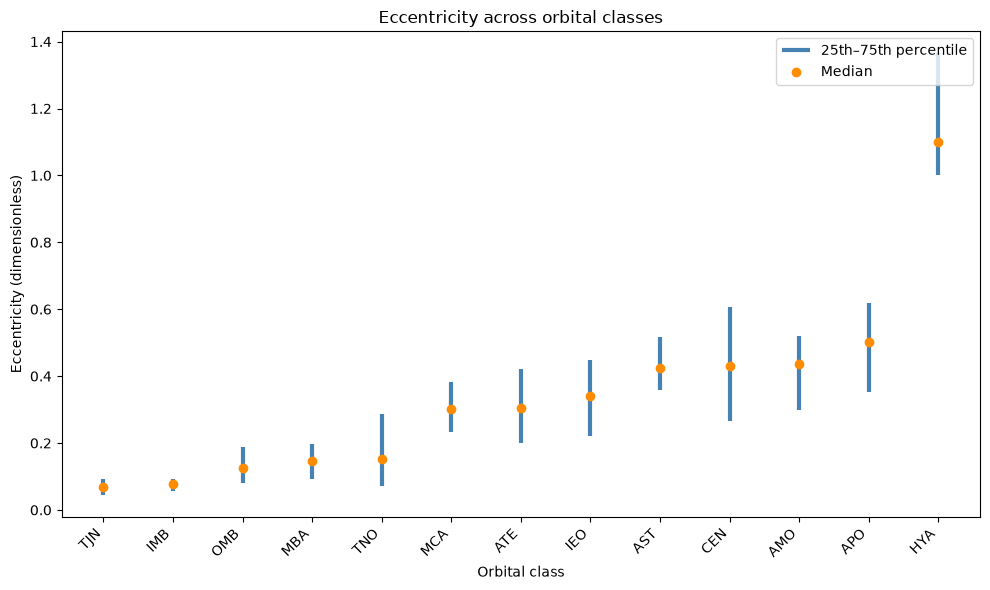

In [45]:
class_data = (
    df[["class", "e"]]
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=["class", "e"])
)

print(f"Original rows: {len(df):,}")
print(f"Rows with orbital class and finite eccentricity: {len(class_data):,}")
print(f"Rows excluded from this comparison: {len(df) - len(class_data):,}")

class_summary = (
    class_data.groupby("class")["e"]
    .agg(
        count="count",
        median="median",
        q25=lambda values: values.quantile(0.25),
        q75=lambda values: values.quantile(0.75)
    )
    .sort_values("median")
)

display(class_summary.round(4))

positions = np.arange(len(class_summary))

fig, ax = plt.subplots(figsize=(10, 6))

ax.vlines(
    positions,
    class_summary["q25"],
    class_summary["q75"],
    color="steelblue",
    linewidth=3,
    label="25th–75th percentile"
)

ax.scatter(
    positions,
    class_summary["median"],
    color="darkorange",
    zorder=3,
    label="Median"
)

ax.set_xticks(positions)
ax.set_xticklabels(class_summary.index, rotation=45, ha="right")
ax.set_xlabel("Orbital class")
ax.set_ylabel("Eccentricity (dimensionless)")
ax.set_title("Eccentricity across orbital classes")
ax.legend()

plt.tight_layout()
plt.show()

## 10. Preliminary observations and preprocessing plan

### 10.1. Evidence recorded in the supplied execution

The values below are transcribed from saved outputs, not from a new execution. Recheck them after rerunning against the team's final CSV.

| Check | Recorded result | Location |
|---|---|---|
| Dataset size | 958,524 rows; 45 columns | Section 3 |
| Object identifiers | Both `id` and `spkid`: 0 missing, 958,524 unique values, 0 repeats | Section 4 |
| Exact duplicates / entirely empty rows | 0 / 0 | Section 6 |
| Diameter availability | 136,209 non-missing; 822,315 missing (85.79%) | Sections 6–7 |
| Albedo availability | 135,103 non-missing; 823,421 missing (85.91%) | Sections 6–7 |
| Name formatting | 513,388 `full_name` values have leading/trailing whitespace | Section 6 |
| Orbital class balance | MBA: 855,954 records (89.30%); HYA: 4 records | Section 8 |
| PHA labels | Y: 2,066; N: 936,537; missing: 19,921 | Section 8 |
| Range checks | 3 finite `per_y` values are non-positive | Section 7 |
| Diameter summary | Median 3.972 km; mean 5.5064 km; maximum 939.4 km | Section 7 |
| H–diameter comparison | 132,045 eligible rows; 10,000 plotted using seed 42 | Section 9 |
| Eccentricity comparison | Group medians include TJN 0.0678, MBA 0.1448, APO 0.5006; group sizes differ | Section 9 |

### 10.2. Decisions to review before preprocessing

| Observed issue | Proposed action | Reason / verification needed |
|---|---|---|
| High missingness in diameter and albedo | Retain columns; use explicit per-question subsets and report row counts | Global complete-case deletion would discard most records. Missingness may be selective. |
| Whitespace in `full_name` | Consider trimming outer whitespace on a separate processed copy | Keep object IDs unchanged and confirm row count and uniqueness are preserved. |
| Non-positive `per_y` values | Inspect these objects alongside `e`, `a`, `class`, `per`, and source records | A stored value may be inapplicable or a placeholder. Do not automatically delete the entire object. |
| `e` reaches 1.8554 and `a` includes negative values | Review exceptional orbit classes before applying elliptical-orbit assumptions | Do not use a blanket rule that every negative `a` or `e >= 1` is a data error. |
| `moid` and `moid_ld` have different missing counts (19,921 vs 127) | Check paired values and source provenance before conversion or filling | Alternate units do not guarantee interchangeable completeness or valid values in this export. |
| Severe class imbalance and very small groups | Report group sizes and choose evaluation methods appropriate to the question | Tiny groups should not support broad conclusions; rare does not mean invalid. |
| Constant `equinox` in this snapshot | Retain as metadata; omit from predictive features if still constant | A reference-frame descriptor does not provide variation for prediction. |

**Status:** These are proposed actions, not completed cleaning operations. This notebook does not export a cleaned dataset. The raw dataframe is retained; filtering in plots operates on temporary subsets.

### 10.3. Team interpretation and question handoff

The team should write its own 3–5 key observations using the evidence above, explaining what each means and its limitations. For every candidate research question, record its owner, required columns, usable sample size, relevant depth criteria, and possible bias or definition-based leakage.

Before finalizing questions, consider:
- Whether diameter/albedo availability differs by orbital class or brightness.
- Whether a relationship is already implied by an equation or classification rule.
- Whether a comparison remains useful after accounting for group composition.
- Whether uncertainty estimates and sample sizes support the intended conclusion.

### 10.4. Completion checklist

- [ ] Confirm the downloaded version, license, source dates, and team motivation.
- [ ] Review and explain the saved findings in the team's own words.
- [ ] Investigate the flagged orbital records and MOID completeness discrepancy.
- [ ] Agree on shared cleaning decisions and log row counts for every transformation.
- [ ] Record significant AI assistance in `LLM_USAGE.md`.
- [ ] Restart and run all cells on the final CSV; save the notebook with outputs.


## 11. Shared preprocessing and export

This section prepares a shared dataset for subsequent analysis.
The original dataframe `df` and the raw CSV remain unchanged.

The following rules apply:

- Remove leading and trailing whitespace from `full_name`.
- Preserve identifiers, missing values, and original row order.
- Do not automatically remove extreme values or rare orbital classes.
- Flag non-positive orbital periods for further investigation.
- Report missingness differences between `moid` and `moid_ld`
  without automatically filling either column.
- Leave question-specific filtering and model-specific preprocessing
  to the analysis and machine-learning notebooks.

The exported dataset is minimally cleaned. Unresolved issues
remain documented and must be considered by downstream users.

In [46]:
required_columns = [
    "id", "spkid", "full_name",
    "per_y", "moid", "moid_ld"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Required columns are missing: {missing_columns}")

# Prevent ambiguous object identification in the shared export.
for col in ["id", "spkid"]:
    if df[col].isna().any() or df[col].duplicated().any():
        raise ValueError(
            f"{col} contains missing or repeated identifiers. "
            "Review these records before exporting."
        )

df_clean = df.copy(deep=True)
cleaning_log = []

print(f"Original shape: {df.shape}")
print(f"Working-copy shape: {df_clean.shape}")

Original shape: (958524, 45)
Working-copy shape: (958524, 45)


### 11.1. Standardize object-name formatting

Only leading and trailing whitespace in `full_name` is removed.
Internal spaces, identifiers, and missing values are preserved.

This is a formatting change: no rows are removed, and no physical
or orbital measurements are modified.

In [47]:
rows_before = len(df_clean)

original_names = df_clean["full_name"].astype("string")
trimmed_names = original_names.str.strip()

changed_mask = (
    original_names.ne(trimmed_names)
    .fillna(False)
)

changed_cells = int(changed_mask.sum())

# Update only affected cells; preserve other values and missing entries.
df_clean.loc[changed_mask, "full_name"] = (
    trimmed_names.loc[changed_mask]
)

cleaning_log.append({
    "Step": "Trim outer whitespace",
    "Column": "full_name",
    "Changed cells": changed_cells,
    "Rows before": rows_before,
    "Rows after": len(df_clean),
    "Reason": "Standardize name formatting without changing object identity"
})

print(f"Names changed: {changed_cells:,}")
print(f"Rows before: {rows_before:,}")
print(f"Rows after: {len(df_clean):,}")

if changed_cells:
    name_examples = pd.DataFrame({
        "Before": original_names.loc[changed_mask].head().map(repr),
        "After": trimmed_names.loc[changed_mask].head().map(repr)
    })
    display(name_examples)

Names changed: 513,388
Rows before: 958,524
Rows after: 958,524


,Before,After
0,' 1 Ceres','1 Ceres'
1,' 2 Pallas','2 Pallas'
2,' 3 Juno','3 Juno'
3,' 4 Vesta','4 Vesta'
4,' 5 Astraea','5 Astraea'


### 11.2. Record unresolved issues

Non-positive finite values of `per_y` are flagged for inspection.
Their interpretation must be checked against orbital parameters
and source records before changing values.

Rows where only one of `moid` and `moid_ld` is missing are also
flagged. This check identifies a completeness difference; it
does not establish which value is correct or validate conversion
between the two units.

Flagged records remain in the shared dataset. Missing labels
are not converted to `N`, and missing physical measurements
are not imputed.

In [48]:
finite_period = (
    df_clean["per_y"].notna()
    & np.isfinite(df_clean["per_y"])
)

period_flag = finite_period & df_clean["per_y"].le(0)

moid_missing = df_clean["moid"].isna()
moid_ld_missing = df_clean["moid_ld"].isna()

# True when exactly one of the two columns is missing.
moid_flag = moid_missing ^ moid_ld_missing

review_columns = [
    col for col in [
        "id", "spkid", "full_name", "class",
        "e", "a", "per", "per_y", "moid", "moid_ld"
    ]
    if col in df_clean.columns
]

review_mask = period_flag | moid_flag

review_records = df_clean.loc[
    review_mask, review_columns
].copy()

review_records["flag_nonpositive_period"] = period_flag.loc[review_mask]
review_records["flag_moid_missingness_mismatch"] = moid_flag.loc[review_mask]

review_summary = pd.DataFrame({
    "Check": [
        "Finite per_y <= 0",
        "moid missing, moid_ld present",
        "moid present, moid_ld missing",
        "Unique rows requiring review"
    ],
    "Count": [
        int(period_flag.sum()),
        int((moid_missing & ~moid_ld_missing).sum()),
        int((~moid_missing & moid_ld_missing).sum()),
        int(review_mask.sum())
    ]
})

display(review_summary)

print("Records with non-positive finite orbital periods:")
display(df_clean.loc[period_flag, review_columns])

print("Sample of MOID completeness differences:")
display(df_clean.loc[moid_flag, review_columns].head(10))

,Check,Count
0,Finite per_y <= 0,3
1,"moid missing, moid_ld present",19794
2,"moid present, moid_ld missing",0
3,Unique rows requiring review,19797


Records with non-positive finite orbital periods:


,id,spkid,full_name,class,e,a,per,per_y,moid,moid_ld
741612,bK13CD4A,3627114,(2013 CA134),HYA,1.855356,-6.149566,NaN,0.0,4.25033,1654.100926
946657,bK19G040,3841499,(A/2019 G4),HYA,1.000398,-14702.447872,NaN,0.0,5.11480,1990.526716
950563,bK19O030,3843487,(A/2019 O3),HYA,1.001173,-7520.984443,NaN,0.0,8.27043,3218.603243


Sample of MOID completeness differences:


,id,spkid,full_name,class,e,a,per,per_y,moid,moid_ld
545163,bJ91R28N,3884244,(1991 RN28),MBA,0.233075,2.245953,1229.417460,3.365962,NaN,0.0
545222,bJ93T11C,3884246,(1993 TC11),MBA,0.353036,2.585657,1518.639592,4.157809,NaN,0.0
545234,bJ94A09F,3884247,(1994 AF9),MBA,0.130933,2.290446,1266.130547,3.466477,NaN,0.0
545251,bJ94G02B,3884248,(1994 GB2),MBA,0.168986,2.368927,1331.760376,3.646161,NaN,0.0
545272,bJ94S04S,3884249,(1994 SS4),MBA,0.140570,2.366254,1329.506423,3.639990,NaN,0.0
545274,bJ94S06X,3884250,(1994 SX6),MBA,0.153173,2.181819,1177.135631,3.222822,NaN,0.0
545289,bJ94T13R,3884251,(1994 TR13),MBA,0.212590,2.154793,1155.331940,3.163126,NaN,0.0
545295,bJ94U10F,3884252,(1994 UF10),MBA,0.184880,2.754252,1669.567076,4.571026,NaN,0.0
545322,bJ95B10C,3884253,(1995 BC10),MBA,0.083893,2.241171,1225.492908,3.355217,NaN,0.0
545326,bJ95B15F,3884254,(1995 BF15),MBA,0.114118,2.530894,1470.650353,4.026421,NaN,0.0


### 11.3. Validate the processed dataframe

Validation checks confirm that:

- Row count, column order, and row order are unchanged.
- Object identifiers remain complete and unique.
- Missing-value counts are unchanged.
- Every column except `full_name` is unchanged.
- Object names match the intended whitespace-trimming operation.

These checks validate the implemented formatting change.
They do not certify that all scientific values are error-free.

In [49]:
# Structure and row order.
assert df_clean.shape == df.shape, "Dataset shape changed."
assert df_clean.columns.equals(df.columns), "Column order changed."
assert df_clean.index.equals(df.index), "Row order changed."

# All non-name columns must remain exactly unchanged.
for col in df.columns:
    if col != "full_name":
        pd.testing.assert_series_equal(df_clean[col], df[col])

# Verify the intended transformation.
pd.testing.assert_series_equal(
    df_clean["full_name"].astype("string"),
    df["full_name"].astype("string").str.strip()
)

# Missingness must remain unchanged in every column.
pd.testing.assert_series_equal(
    df_clean.isna().sum(),
    df.isna().sum()
)

# Confirm identifier integrity.
for col in ["id", "spkid"]:
    assert df_clean[col].notna().all(), f"Missing identifiers in {col}."
    assert df_clean[col].is_unique, f"Repeated identifiers in {col}."

cleaning_log_df = pd.DataFrame(cleaning_log)

print("All validation checks passed.")
print(f"Final shape: {df_clean.shape}")
display(cleaning_log_df)

All validation checks passed.
Final shape: (958524, 45)


,Step,Column,Changed cells,Rows before,Rows after,Reason
0,Trim outer whitespace,full_name,513388,958524,958524,Standardize name formatting without changing o...


### 11.4. Export and handoff

The following files are written to `data/processed/`:

| File | Purpose |
|---|---|
| `asteroids_clean.csv` | Shared dataset with standardized object-name formatting |
| `cleaning_log.csv` | Implemented changes and row counts |
| `records_to_review.csv` | Flagged records and review indicators |
| `quality_review_summary.csv` | Counts of unresolved issues |

Rerunning the export cell replaces these generated files.
The raw CSV is not modified.

Downstream users should inspect the review files and document
any additional exclusions. Missing measurements and labels
remain missing. Machine-learning imputation, scaling, and
encoding must be fitted within the training pipeline.

CSV does not preserve pandas data types. When reloading,
explicitly read identifier columns as strings where appropriate.

In [50]:
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_tables = {
    "asteroids_clean.csv": df_clean,
    "cleaning_log.csv": cleaning_log_df,
    "records_to_review.csv": review_records,
    "quality_review_summary.csv": review_summary
}

raw_path = DATA_PATH.resolve()

for filename, table in output_tables.items():
    output_path = OUTPUT_DIR / filename

    if output_path.resolve() == raw_path:
        raise ValueError("Refusing to overwrite the raw dataset.")

    table.to_csv(output_path, index=False, encoding="utf-8")

    print(
        f"Saved: {output_path.name} | "
        f"Rows: {len(table):,} | "
        f"Size: {output_path.stat().st_size / (1024 ** 2):.2f} MB"
    )

Saved: asteroids_clean.csv | Rows: 958,524 | Size: 433.62 MB
Saved: cleaning_log.csv | Rows: 1 | Size: 0.00 MB
Saved: records_to_review.csv | Rows: 19,797 | Size: 1.87 MB
Saved: quality_review_summary.csv | Rows: 4 | Size: 0.00 MB


## 12. References

- [Kaggle Asteroid Dataset](https://www.kaggle.com/datasets/sakhawat18/asteroid-dataset)


- [JPL SBDB field documentation](https://ssd-api.jpl.nasa.gov/doc/sbdb_query.html)
- [JPL SBDB orbital parameters](https://ssd-api.jpl.nasa.gov/doc/sbdb.html)
- [JPL orbital classifications](https://ssd-api.jpl.nasa.gov/doc/sbdb_filter.html)
- [CNEOS near-Earth and potentially hazardous classifications](https://cneos.jpl.nasa.gov/about/neo_groups.html)
- [CNEOS asteroid size estimation](https://cneos.jpl.nasa.gov/tools/ast_size_est.html)
Add source access dates and the public notebooks actually consulted.
